<a href="https://colab.research.google.com/github/JUAN-VILLOTA/har-smartphones-ml-grupo11/blob/main/01_descripcion_y_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition Using Smartphones — Grupo 11
## Parte 1. Descripción del problema y análisis exploratorio

**Integrantes:** Juan David Villota Córdoba y Sammir Alejandro Bolaños Luna  
**Curso:** Introducción al Aprendizaje Automático — Universidad de Antioquia, 2026-2  
**Base de datos:** [Human Activity Recognition Using Smartphones (UCI)](https://doi.org/10.24432/C54S4K)

**Qué hace este notebook:** descarga la base de datos, la organiza en tablas, revisa su calidad, describe la distribución de las actividades y de los voluntarios, y genera la figura del primer informe (`fig_eda.png`). No entrena modelos.

**Cómo ejecutarlo:** abrirlo en Colab y usar *Entorno de ejecución → Ejecutar todo*. Descarga los datos directamente de UCI; no necesita archivos locales.


## 1. Entender el problema

Treinta voluntarios (19 a 48 años) llevaron un **Samsung Galaxy S II en la cintura** mientras realizaban seis actividades: caminar, subir escaleras, bajar escaleras, estar sentado, estar de pie y estar acostado. El teléfono registró el acelerómetro y el giroscopio en tres ejes a 50 Hz. Las sesiones se grabaron en video para asignar manualmente las etiquetas.

Las señales se cortaron en **ventanas de 2,56 s (128 lecturas) con 50 % de traslape**, y de cada ventana los autores calcularon **561 características** en el dominio del tiempo y de la frecuencia. Por eso cada fila de la tabla es una ventana, no una lectura del sensor.

El problema es una **clasificación supervisada multiclase**: a partir de las 561 características de una ventana, predecir cuál de las seis actividades ocurre.

## 2. Preparar las herramientas

Importamos las bibliotecas que usaremos para leer, organizar y visualizar los datos. En esta etapa todavía no entrenamos modelos.

In [1]:
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

## 3. Descargar y abrir la base

Descargamos la versión publicada en UCI y abrimos el ZIP **en memoria**, sin guardar archivos en disco. El ZIP de UCI trae adentro otro ZIP (`UCI HAR Dataset.zip`), así que, si existe, abrimos también ese.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

with urllib.request.urlopen(URL) as respuesta:
    z = zipfile.ZipFile(io.BytesIO(respuesta.read()))

# Si hay un ZIP dentro del ZIP, abrimos el interno
internos = [n for n in z.namelist() if n.endswith(".zip")]
if internos:
    z = zipfile.ZipFile(io.BytesIO(z.read(internos[0])))

print("Archivos en la base:", len(z.namelist()))

Archivos en la base: 74


## 4. Crear una función de lectura

Los archivos de UCI tienen valores separados por espacios y no traen encabezados. La función `leer` busca un archivo por el final de su ruta y lo carga como tabla.

Se excluye la carpeta `Inertial Signals` (señales crudas, 128 lecturas por ventana) porque en este proyecto usamos las 561 características ya calculadas.

In [3]:
def leer(sufijo, **kw):
    """Carga el archivo cuya ruta termina en `sufijo` (sin encabezados, separado por espacios)."""
    ruta = [n for n in z.namelist() if n.endswith(sufijo) and "Inertial" not in n][0]
    return pd.read_csv(z.open(ruta), sep=r"\s+", header=None, **kw)

## 5. Nombres de las características y de las actividades

`features.txt` contiene los 561 nombres de las características y `activity_labels.txt` la correspondencia entre el código (1 a 6) y la actividad.

In [4]:
features = leer("features.txt")[1].tolist()
etiquetas = leer("activity_labels.txt").set_index(0)[1].to_dict()

print("Número de características:", len(features))
print("Nombres de características repetidos:", len(features) - len(set(features)))
print("Actividades:")
for codigo, actividad in etiquetas.items():
    print(f"  {codigo}: {actividad}")

Número de características: 561
Nombres de características repetidos: 84
Actividades:
  1: WALKING
  2: WALKING_UPSTAIRS
  3: WALKING_DOWNSTAIRS
  4: SITTING
  5: STANDING
  6: LAYING


Algunos nombres están repetidos en el archivo original. Para evitar columnas ambiguas, añadimos un sufijo (`_2`, `_3`) solo a las repeticiones. **No eliminamos ninguna característica.**

In [5]:
vistos = {}
nombres = []
for nombre in features:
    vistos[nombre] = vistos.get(nombre, 0) + 1
    nombres.append(nombre if vistos[nombre] == 1 else f"{nombre}_{vistos[nombre]}")

print("Columnas listas:", len(nombres))
print("¿Todos los nombres son únicos?", len(nombres) == len(set(nombres)))

Columnas listas: 561
¿Todos los nombres son únicos? True


Para las tablas y figuras usamos el orden y los nombres en español de las actividades: primero las tres dinámicas y luego las tres estáticas.

In [6]:
orden = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

nombres_es = {
    "WALKING": "Caminar",
    "WALKING_UPSTAIRS": "Subir escaleras",
    "WALKING_DOWNSTAIRS": "Bajar escaleras",
    "SITTING": "Sentado",
    "STANDING": "De pie",
    "LAYING": "Acostado",
}

## 6. Cargar entrenamiento y prueba

UCI proporciona una partición oficial **por voluntario**: 7 352 ventanas para entrenamiento y 2 947 para prueba. A cada ventana le agregamos tres columnas:

- `actividad`: la etiqueta que queremos predecir.
- `sujeto`: el identificador del voluntario. **No se usa como entrada del modelo**; solo sirve para construir las particiones de validación.
- `conjunto`: si la ventana pertenece a entrenamiento o a prueba.

In [7]:
partes = {}
for conjunto in ["train", "test"]:
    X = leer(f"X_{conjunto}.txt")
    X.columns = nombres
    X["actividad"] = leer(f"y_{conjunto}.txt")[0].map(etiquetas)
    X["sujeto"] = leer(f"subject_{conjunto}.txt")[0]
    X["conjunto"] = conjunto
    partes[conjunto] = X

print("Entrenamiento:", len(partes["train"]))
print("Prueba:", len(partes["test"]))

Entrenamiento: 7352
Prueba: 2947


### Primera mirada a las observaciones

Cada fila es una ventana de 2,56 s. Las 561 características la describen; `actividad` es la etiqueta; `sujeto` y `conjunto` son metadatos para el análisis, no características predictoras.

In [8]:
df = pd.concat(partes.values(), ignore_index=True)
print("Dimensiones totales (filas, columnas):", df.shape)
display(df[nombres[:6] + ["actividad", "sujeto", "conjunto"]].head())

Dimensiones totales (filas, columnas): (10299, 564)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,actividad,sujeto,conjunto
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,STANDING,1,train
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,STANDING,1,train
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,STANDING,1,train
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,STANDING,1,train
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,STANDING,1,train


## 7. Revisar la calidad de los datos

Verificamos valores faltantes, tipos de datos, rango de valores y filas duplicadas para decidir si se necesita limpieza o imputación.

In [9]:
X_all = df[nombres]
print("Valores faltantes (NaN):", int(X_all.isna().sum().sum()))
print("Tipos de datos:", X_all.dtypes.value_counts().to_dict())
print("Mínimo global:", X_all.min().min(), "| Máximo global:", X_all.max().max())
print("Filas duplicadas:", int(X_all.duplicated().sum()))

Valores faltantes (NaN): 0
Tipos de datos: {dtype('float64'): 561}
Mínimo global: -1.0 | Máximo global: 1.0
Filas duplicadas: 0


**Cómo interpretar el resultado:**

- Si no hay valores faltantes, no se necesita imputación.
- Las características ya vienen acotadas entre -1 y 1, pero eso no significa que tengan la misma dispersión. Para los modelos sensibles a la escala (SVM, KNN y red neuronal) se aplicará `StandardScaler` **dentro de un Pipeline**, ajustado solo con los datos de entrenamiento de cada partición.

## 8. Distribución de las actividades

Contamos las ventanas de cada actividad en entrenamiento y en prueba para ver si alguna clase está poco representada.

In [10]:
tabla = pd.crosstab(df["actividad"], df["conjunto"]).reindex(orden)[["train", "test"]]
tabla["total"] = tabla.sum(axis=1)
tabla["%"] = (100 * tabla["total"] / tabla["total"].sum()).round(1)
tabla.index = [nombres_es[a] for a in tabla.index]
tabla

conjunto,train,test,total,%
Caminar,1226,496,1722,16.7
Subir escaleras,1073,471,1544,15.0
Bajar escaleras,986,420,1406,13.7
Sentado,1286,491,1777,17.3
De pie,1374,532,1906,18.5
Acostado,1407,537,1944,18.9


In [11]:
razon = tabla["total"].max() / tabla["total"].min()
print(f"Relación entre la clase más grande y la más pequeña: {razon:.2f} a 1")

Relación entre la clase más grande y la más pequeña: 1.38 a 1


**Decisión sobre el balance de clases:** las clases van de 13,7 % a 18,9 % del total, una relación cercana a 1,4 a 1. Es un desbalance leve, por lo que **no se aplica sobremuestreo ni submuestreo**: generar ventanas sintéticas o descartar ventanas reales no compensaría una diferencia tan pequeña. Aun así, se reportarán métricas por clase y el F1 macro, que pesa igual cada actividad, para no ocultar fallos en una clase concreta.

## 9. Voluntarios: base de la evaluación independiente del sujeto

Comprobamos tres cosas que sostienen la metodología de validación:

1. Ningún voluntario aparece a la vez en entrenamiento y en prueba.
2. Cuántos voluntarios hay en cada conjunto.
3. Si todos los voluntarios realizaron las seis actividades. Si es así, al separar por voluntario cada partición sigue conteniendo todas las clases.

In [12]:
sujetos_train = set(partes["train"]["sujeto"])
sujetos_test = set(partes["test"]["sujeto"])

print("Voluntarios en entrenamiento:", len(sujetos_train))
print("Voluntarios en prueba:", len(sujetos_test))
print("Voluntarios en ambos conjuntos:", len(sujetos_train & sujetos_test))

Voluntarios en entrenamiento: 21
Voluntarios en prueba: 9
Voluntarios en ambos conjuntos: 0


In [13]:
ventanas = pd.crosstab(df["sujeto"], df["actividad"])[orden]
ventanas.columns = [nombres_es[a] for a in orden]

print("¿Todos los voluntarios hicieron las 6 actividades?", bool((ventanas > 0).all().all()))
print("Ventanas por voluntario: mínimo", ventanas.sum(axis=1).min(),
      "| máximo", ventanas.sum(axis=1).max())
ventanas

¿Todos los voluntarios hicieron las 6 actividades? True
Ventanas por voluntario: mínimo 281 | máximo 409


,Caminar,Subir escaleras,Bajar escaleras,Sentado,De pie,Acostado
sujeto,,,,,,
1,95,53,49,47,53,50
2,59,48,47,46,54,48
3,58,59,49,52,61,62
4,60,52,45,50,56,54
5,56,47,47,44,56,52
6,57,51,48,55,57,57
7,57,51,47,48,53,52
8,48,41,38,46,54,54
9,52,49,42,50,45,50


**Por qué importa:** las ventanas de una misma persona se parecen mucho entre sí y dos ventanas consecutivas comparten el 50 % de sus lecturas. Si se repartieran al azar, el modelo se evaluaría con casi copias de lo que vio en entrenamiento (fuga de información) y el desempeño saldría optimista. Por eso se respeta la partición oficial y, dentro del entrenamiento, los hiperparámetros se ajustarán con validación cruzada agrupada por voluntario (`GroupKFold`).

## 10. Visualización exploratoria

La figura (a) muestra cuántas ventanas hay por actividad. La figura (b) proyecta las ventanas de entrenamiento en sus dos primeras componentes principales para observar patrones y solapamientos entre clases.

**Importante:** esta PCA es solo exploratoria y se ajusta únicamente con el conjunto de entrenamiento. La reducción de dimensión formal se hará más adelante, con el escalador y la PCA dentro de cada partición de validación.

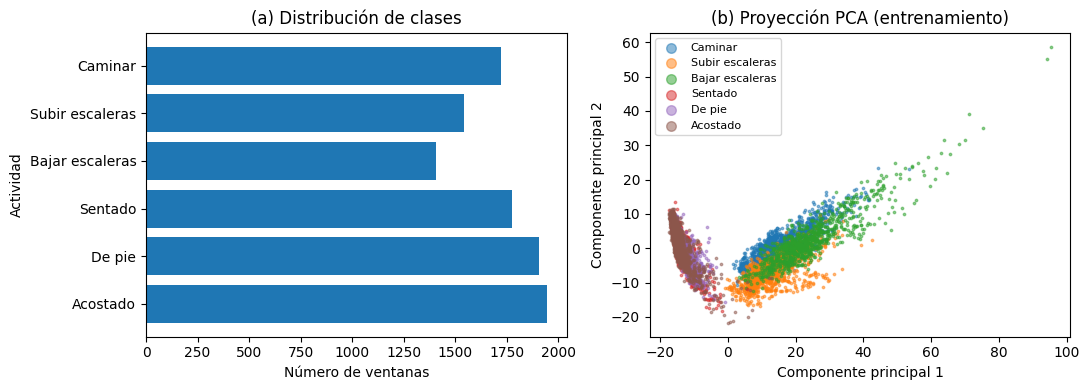

In [14]:
tr = partes["train"]
Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(tr[nombres]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].barh(tabla.index, tabla["total"].values)
ax[0].invert_yaxis()
ax[0].set_xlabel("Número de ventanas")
ax[0].set_ylabel("Actividad")
ax[0].set_title("(a) Distribución de clases")

for act in orden:
    m = tr["actividad"].values == act
    ax[1].scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.5, label=nombres_es[act])
ax[1].set_xlabel("Componente principal 1")
ax[1].set_ylabel("Componente principal 2")
ax[1].set_title("(b) Proyección PCA (entrenamiento)")
ax[1].legend(markerscale=4, fontsize=8)

fig.tight_layout()
fig.savefig("fig_eda.png", dpi=200)
plt.show()

**Lectura de la figura (b):** las actividades estáticas (sentado, de pie y acostado) se agrupan separadas de las dinámicas (caminar, subir y bajar escaleras). Dentro de cada grupo las clases se superponen; en particular, sentado y de pie ocupan casi la misma región, lo que anticipa la confusión entre ambas reportada por Anguita et al. (2013).

## 11. Conclusiones del análisis exploratorio

- La base tiene 10 299 ventanas, 561 características numéricas y 6 actividades; no hay valores faltantes ni filas duplicadas, así que no se requiere imputación ni limpieza.
- Hay nombres de características repetidos en el archivo original; se renombraron sin eliminar columnas.
- Las clases están razonablemente balanceadas (13,7 % a 18,9 %); no se aplica sobremuestreo, pero se reportarán F1 macro y matriz de confusión.
- La partición oficial separa a los voluntarios entre entrenamiento y prueba, y todos realizaron las seis actividades. La validación se hará agrupada por voluntario.
- La proyección PCA separa actividades estáticas de dinámicas, pero sentado y de pie se superponen: es el error que esperamos encontrar en los modelos.

**Siguiente notebook:** entrenamiento y evaluación de los modelos con validación agrupada por voluntario.